In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats

# **1 Import to csv**

In [5]:
df = pd.read_csv(r'C:\users\admin\Downloads\social_media_engagement_5000.csv')
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


# **Data Type**

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

#  **Date columns to datetime**

In [12]:
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    format='%d-%m-%Y',
    errors='coerce'
)

In [13]:
print(df['posted_at'].dtype)

datetime64[us]


# **Numpay basic array operation**

In [13]:
#numpy for basic array operation
likes_array = np.array([100,200,300,400,500])

print("Likes:", likes_array)
print("Total Likes:", np.sum(likes_array))
print("Average Likes:", np.mean(likes_array))
print("maximum Likes:", np.max(likes_array))
print("minimum Likes:", np.min(likes_array))

Likes: [100 200 300 400 500]
Total Likes: 1500
Average Likes: 300.0
maximum Likes: 500
minimum Likes: 100


 # **2 Data cleaning**

In [14]:
#cleaning missing data
print(df.isnull().sum())

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64


In [15]:
df['age'] = df['age'].fillna(df['age'].median())
df['likes'] = df['likes'].fillna(df['likes'].median())
df['comments'] = df['comments'].fillna(df['comments'].median())
df['shares'] = df['shares'].fillna(df['shares'].median())


In [16]:
df['gender'] = df['gender'].fillna(df['gender'].mode()[0])
df['sentiment'] =df['sentiment'].fillna(df['sentiment'].mode()[0])

In [17]:
print(df.isnull().sum())

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


# **Duplicate records**

In [20]:
#duplicate records
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [21]:
#remove duplicate
df = df.drop_duplicates()

In [4]:
categorical_columns = [
     'gender',
     'country',
     'post_type',
     'post_category',
     'device_type',
     'sentiment'
 ]
 
for col in categorical_columns:
    df[col] =df[col].astype(str).str.strip().str.lower()

In [6]:
print(df[['age','likes','comments','shares',]].describe())

               age         likes     comments       shares
count  4850.000000   4850.000000  4850.000000  4850.000000
mean     38.454021  10107.043711  1502.195670  1002.629485
std      14.912381   5789.819252   869.537889   579.615158
min      13.000000     10.000000     0.000000     0.000000
25%      26.000000   5068.500000   760.000000   498.000000
50%      38.000000  10105.500000  1497.000000  1012.000000
75%      51.000000  15115.000000  2256.000000  1501.000000
max      64.000000  19998.000000  2999.000000  1999.000000


In [8]:
print("Negative likes:",(df['likes'] < 0).sum())
print("Negative comments:",(df['comments'] < 0).sum())
print("Negative shares:",(df['shares'] < 0).sum())
      
      

Negative likes: 0
Negative comments: 0
Negative shares: 0


In [13]:
df['Hashtag_count'] =df['hashtags'].str.findall(r'#\w+').str.len()

In [15]:
df['sentiment'] =df['sentiment'].str.strip().str.lower()
print(df['sentiment'].unique())

<ArrowStringArray>
['negative', 'positive', 'neutral', nan]
Length: 4, dtype: str


# **3 Data exploration using pandas**

In [16]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,Hashtag_count
0,25795,43.0,female,brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,uk,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,france,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,uk,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372,1


In [17]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,Hashtag_count
4995,59500,44.0,male,australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,other,uae,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63.0,female,usa,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,female,germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,other,japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,04-03-2023,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


In [18]:
df.shape

(5000, 20)

In [19]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'Hashtag_count'],
      dtype='str')

In [20]:
df.info

<bound method DataFrame.info of       user_id   age  gender    country  post_id post_type post_category  \
0       25795  43.0  female     brazil   496713     image       fitness   
1       10860  33.0    male     brazil   157326      reel          food   
2       86820  32.0  female         uk   109864      text          food   
3       64886  51.0   other     france   848877      text       fitness   
4       16265  34.0   other         uk   449706     image       fitness   
...       ...   ...     ...        ...      ...       ...           ...   
4995    59500  44.0    male  australia   441541     video     education   
4996    22100  38.0   other        uae   677076      reel     education   
4997    67021  63.0  female        usa   273595      text        travel   
4998    29800  13.0  female    germany   785644     video       fitness   
4999    73400  54.0   other      japan   712252      text        travel   

        likes  comments  shares  watch_time_sec  impression_count  

In [21]:
df.dtypes

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
Hashtag_count         int64
dtype: object

In [22]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,Hashtag_count
count,5000.000000,4850.000000,5000.000000,4850.000000,4850.000000,4850.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.454021,548042.909000,10107.043711,1502.195670,1002.629485,4014.503200,50013.732800,393698.224800,0.964356,1.998600
std,26090.370121,14.912381,260646.957267,5789.819252,869.537889,579.615158,2308.096459,28844.939104,230927.884535,5.318029,0.812853
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.000000,0.000000,105.000000,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5068.500000,760.000000,498.000000,2017.750000,24988.250000,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.000000,4034.500000,49934.500000,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,15115.000000,2256.000000,1501.000000,6020.250000,74662.250000,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.000000,7998.000000,99995.000000,799533.000000,191.504348,3.000000


In [24]:
df['gender'].value_counts()

gender
male      1699
other     1581
female    1570
Name: count, dtype: int64

In [25]:
df['post_type'].value_counts()

post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

In [26]:
df['post_category'].value_counts()

post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64

In [27]:
df['sentiment'].value_counts()

sentiment
positive    2363
neutral     1527
negative     960
Name: count, dtype: int64

In [28]:
print(df['post_type'].unique())
print(df['gender'].unique())
print(df['sentiment'].unique())

<ArrowStringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str
<ArrowStringArray>
['female', 'male', 'other', nan]
Length: 4, dtype: str
<ArrowStringArray>
['negative', 'positive', 'neutral', nan]
Length: 4, dtype: str


In [33]:
print("Unique post types:",df['post_type'].nunique())
print("Unique countries:",df['country'].nunique())
print("Unique categories:",
df['post_category'].nunique())

Unique post types: 4
Unique countries: 10
Unique categories: 8


In [34]:
#correlation matrix

numeric_df = df.select_dtypes(include='number')
correlation =numeric_df.corr()
print(correlation)

                   user_id       age   post_id     likes  comments    shares  \
user_id           1.000000 -0.006789  0.020051  0.026228 -0.033874  0.014004   
age              -0.006789  1.000000 -0.013353 -0.037371 -0.007491  0.014348   
post_id           0.020051 -0.013353  1.000000  0.014773 -0.010724  0.001901   
likes             0.026228 -0.037371  0.014773  1.000000 -0.018980  0.004799   
comments         -0.033874 -0.007491 -0.010724 -0.018980  1.000000  0.006310   
shares            0.014004  0.014348  0.001901  0.004799  0.006310  1.000000   
watch_time_sec   -0.016847  0.005677  0.018374  0.008837 -0.016616  0.014898   
impression_count  0.015326  0.013513 -0.007709  0.008067 -0.009537 -0.005178   
follower_count    0.010124 -0.025416 -0.002844 -0.023331 -0.011921 -0.010891   
engagement_rate  -0.004282  0.008044  0.010139  0.093555  0.000046  0.021804   
Hashtag_count    -0.013692  0.007336  0.007344 -0.002224 -0.015450  0.013642   

                  watch_time_sec  impre

In [35]:
 print(df.groupby('post_type')['likes'].mean())                                                                                                                                                                                              

post_type
image    10104.848560
reel     10035.341680
text     10099.975124
video    10190.972292
Name: likes, dtype: float64


In [36]:
print(df.groupby('country')['impression_count'].mean())

country
australia    48346.383367
brazil       49193.174603
canada       48703.150097
france       51727.673387
germany      48605.406122
india        52462.386916
japan        49616.135593
uae          48928.413519
uk           51119.393509
usa          51263.872255
Name: impression_count, dtype: float64


# **4 Data wrangling**

In [37]:
#4 data wrangling

df['engagement_score'] = (df['likes'] + df['comments'] + df['shares'])
print(df[['likes','comments','shares','engagement_score']].head())

     likes  comments  shares  engagement_score
0   7011.0     354.0  1157.0            8522.0
1  11750.0    2606.0  1807.0           16163.0
2   4862.0     344.0   955.0            6161.0
3   5350.0    1083.0  1049.0            7482.0
4  12682.0    2735.0  1300.0           16717.0


In [40]:
df['log_likes'] = np.log1p(df['likes'])
df['log_comments'] = np.log1p(df['comments'])
df['log_shares'] = np.log1p(df['shares'])

In [41]:
post_type_summary = df.groupby('post_type').agg(
    average_likes=('likes','mean'),
    average_comments=('comments','mean'),
    average_share=('shares','mean'),
    average_engagment=('engagement_rate','mean'))

print(post_type_summary)

           average_likes  average_comments  average_share  average_engagment
post_type                                                                   
image       10104.848560       1526.123242    1019.506193           0.895646
reel        10035.341680       1504.430298     981.102894           0.783047
text        10099.975124       1499.170530    1014.052196           1.064549
video       10190.972292       1478.666107     996.361953           1.122365


In [43]:
country_summary = df.groupby('country').agg(
    average_likes=('likes','mean'),
    average_impressions=('impression_count','mean'),
    average_engagement=('engagement_rate','mean'))
print(country_summary)

           average_likes  average_impressions  average_engagement
country                                                          
australia   10300.861345         48346.383367            1.324339
brazil       9881.807302         49193.174603            1.540704
canada      10062.049900         48703.150097            0.916659
france      10380.072464         51727.673387            1.146402
germany     10131.687366         48605.406122            0.759000
india        9955.456863         52462.386916            0.655005
japan       10088.502165         49616.135593            0.769623
uae         10230.979550         48928.413519            1.112352
uk           9931.050000         51119.393509            0.850966
usa         10122.775051         51263.872255            0.576580


In [46]:
sentiment_summary = df.groupby('sentiment').agg(
    average_likes=('likes','mean'),
    average_comments=('comments','mean'),
    average_shares=('shares','mean'),
    average_engagement=('engagement_rate','mean'))
print(sentiment_summary)

           average_likes  average_comments  average_shares  average_engagement
sentiment                                                                     
negative    10211.406452       1516.584402     1007.186966            1.038486
neutral      9917.785570       1529.270525      996.149966            0.991170
positive    10158.542994       1481.890057     1001.503073            0.954800


In [53]:
print(df.columns.tolist())

['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'Hashtag_count', 'engagement_score', 'log_likes', 'log_comments', 'log_shares']


# **5 statistical analysis**

In [54]:
#stastistcal analysis
analysis_columns = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate',
    'follower_count'
]

In [55]:
#calculate mean

print(df[analysis_columns].mean())

likes               10107.043711
comments             1502.195670
shares               1002.629485
watch_time_sec       4014.503200
engagement_rate         0.964356
follower_count     393698.224800
dtype: float64


In [58]:
#calculate meadian

print(df[analysis_columns].median())

likes               10105.500000
comments             1497.000000
shares               1012.000000
watch_time_sec       4034.500000
engagement_rate         0.253896
follower_count     388982.000000
dtype: float64


In [59]:
#calculate mode

print(df[analysis_columns].mode())

        likes  comments  shares  watch_time_sec  engagement_rate  \
0      6486.0    2934.0   138.0           916.0         0.006363   
1      8151.0       NaN   319.0          2145.0         0.007420   
2     10943.0       NaN   397.0          4360.0         0.012676   
3     13536.0       NaN   424.0          7003.0         0.012692   
4     15718.0       NaN   437.0          7688.0         0.015005   
...       ...       ...     ...             ...              ...   
4995      NaN       NaN     NaN             NaN        87.266094   
4996      NaN       NaN     NaN             NaN        92.828829   
4997      NaN       NaN     NaN             NaN       105.752212   
4998      NaN       NaN     NaN             NaN       121.931973   
4999      NaN       NaN     NaN             NaN       191.504348   

      follower_count  
0           497502.0  
1                NaN  
2                NaN  
3                NaN  
4                NaN  
...              ...  
4995             NaN  

In [60]:
#Calculate standard deviation

print(df[analysis_columns].std())

likes                5789.819252
comments              869.537889
shares                579.615158
watch_time_sec       2308.096459
engagement_rate         5.318029
follower_count     230927.884535
dtype: float64


In [61]:
#Calculate variance

print(df[analysis_columns].var())

likes              3.352201e+07
comments           7.560961e+05
shares             3.359537e+05
watch_time_sec     5.327309e+06
engagement_rate    2.828143e+01
follower_count     5.332769e+10
dtype: float64


In [62]:
#Calculate percentiles

print(df[analysis_columns].quantile([0.25, 0.50, 0.75, 0.90]))

        likes  comments  shares  watch_time_sec  engagement_rate  \
0.25   5068.5     760.0   498.0         2017.75         0.145781   
0.50  10105.5    1497.0  1012.0         4034.50         0.253896   
0.75  15115.0    2256.0  1501.0         6020.25         0.504794   
0.90  18076.1    2702.1  1800.1         7212.10         1.201200   

      follower_count  
0.25       194480.00  
0.50       388982.00  
0.75       589744.25  
0.90       717755.90  


In [63]:
#Calculate skewness and kurtosis

print("Skewness:")
print(df[analysis_columns].skew())

print("Kurtosis:")
print(df[analysis_columns].kurt())

Skewness:
likes              -0.006813
comments            0.003206
shares             -0.012977
watch_time_sec     -0.018196
engagement_rate    18.781271
follower_count      0.041118
dtype: float64
Kurtosis:
likes               -1.205547
comments            -1.200096
shares              -1.202503
watch_time_sec      -1.195652
engagement_rate    482.991739
follower_count      -1.189474
dtype: float64


# **6 Data visualization**

# **Matplotlib**

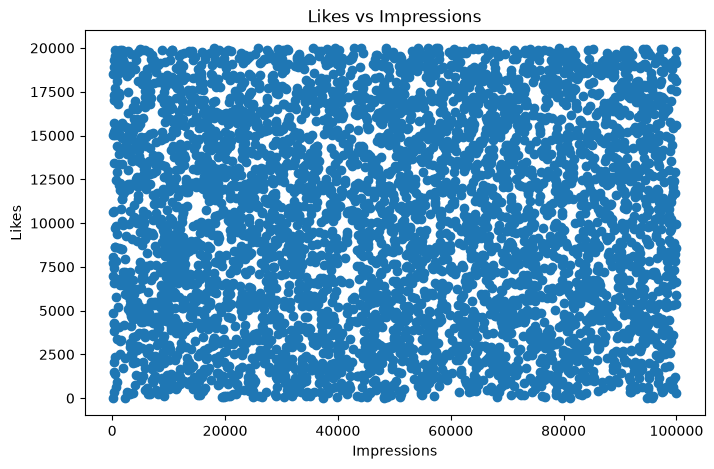

In [64]:

1#Scatter Plot: Likes vs Impressionsmatplotlib

plt.figure(figsize=(8, 5))

plt.scatter(df['impression_count'], df['likes'])

plt.xlabel('Impressions')
plt.ylabel('Likes')
plt.title('Likes vs Impressions')

plt.show()

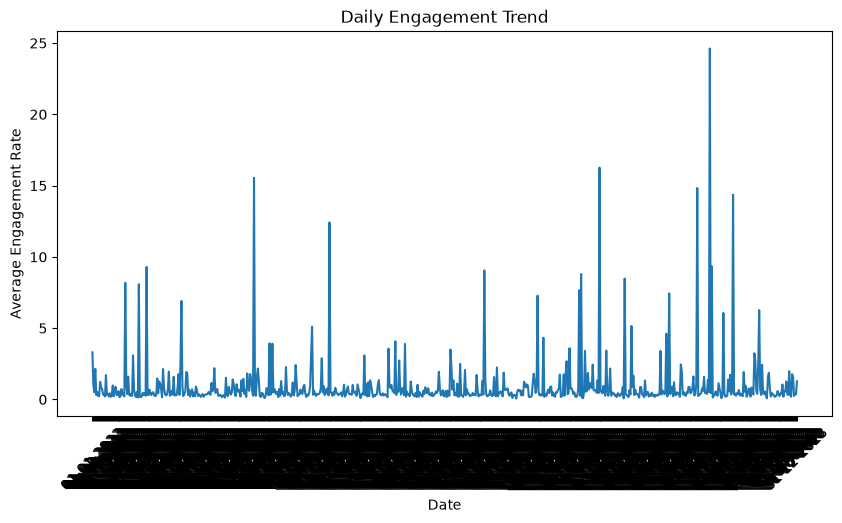

In [65]:
2#Line Plot: Daily Engagement Trend

daily_engagement = df.groupby('posted_at')['engagement_rate'].mean()

plt.figure(figsize=(10, 5))

plt.plot(daily_engagement.index, daily_engagement.values)

plt.xlabel('Date')
plt.ylabel('Average Engagement Rate')
plt.title('Daily Engagement Trend')

plt.xticks(rotation=45)

plt.show()

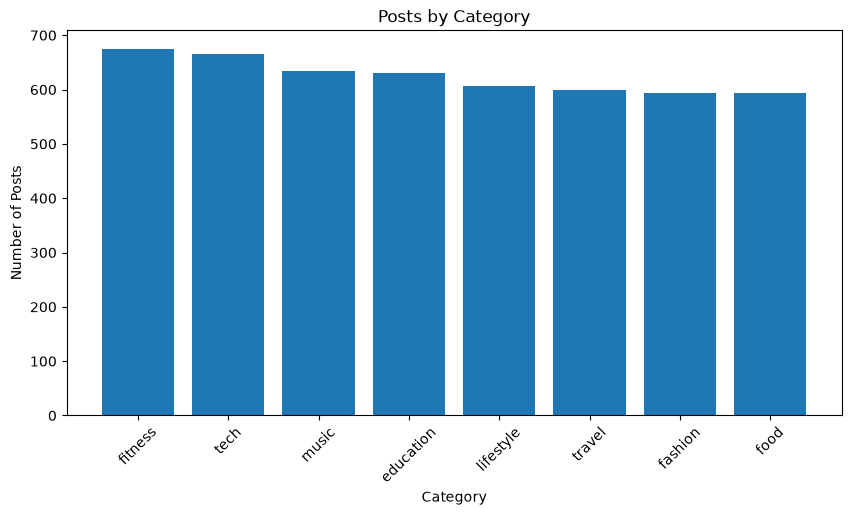

In [66]:
3#Bar Chart: Posts by Category

category_count = df['post_category'].value_counts()

plt.figure(figsize=(10, 5))

plt.bar(category_count.index, category_count.values)

plt.xlabel('Category')
plt.ylabel('Number of Posts')
plt.title('Posts by Category')

plt.xticks(rotation=45)

plt.show()

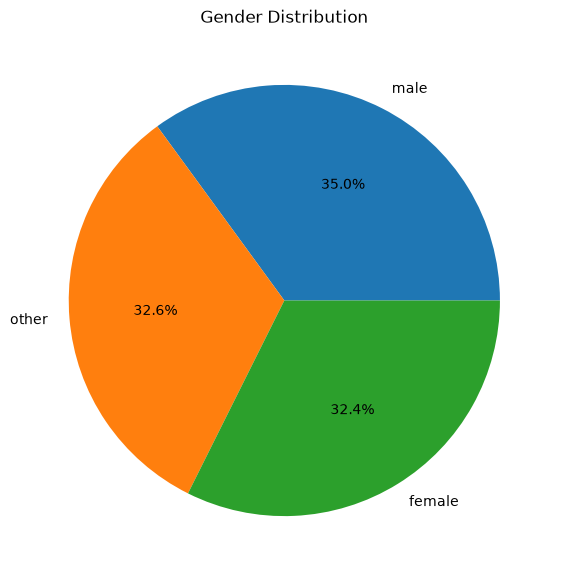

In [67]:
4#Pie Chart: Gender Distribution

gender_count = df['gender'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    gender_count.values,
    labels=gender_count.index,
    autopct='%1.1f%%'
)

plt.title('Gender Distribution')

plt.show()

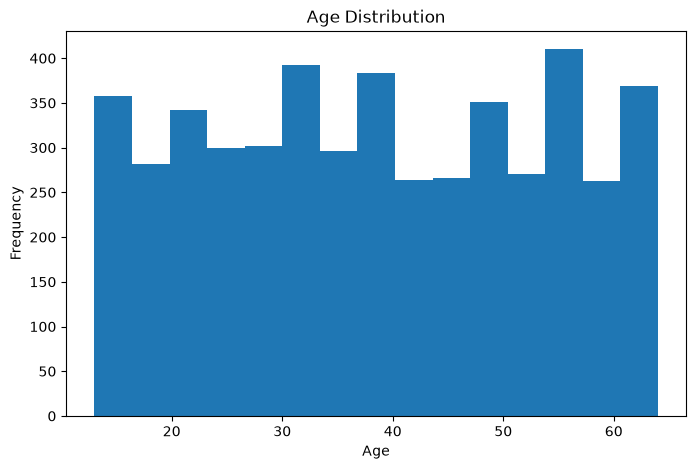

In [68]:
5#Histogram: Age Distribution

plt.figure(figsize=(8, 5))

plt.hist(df['age'], bins=15)

plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')

plt.show()

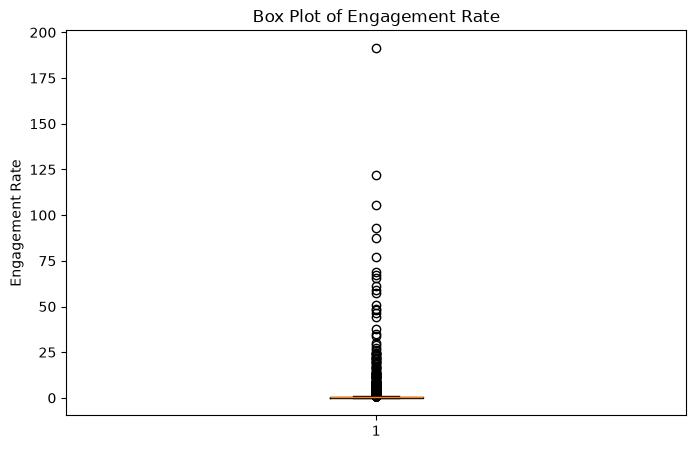

In [69]:
6#Box Plot: Engagement Rate

plt.figure(figsize=(8, 5))

plt.boxplot(df['engagement_rate'])

plt.ylabel('Engagement Rate')
plt.title('Box Plot of Engagement Rate')

plt.show()

# **Seaborn**

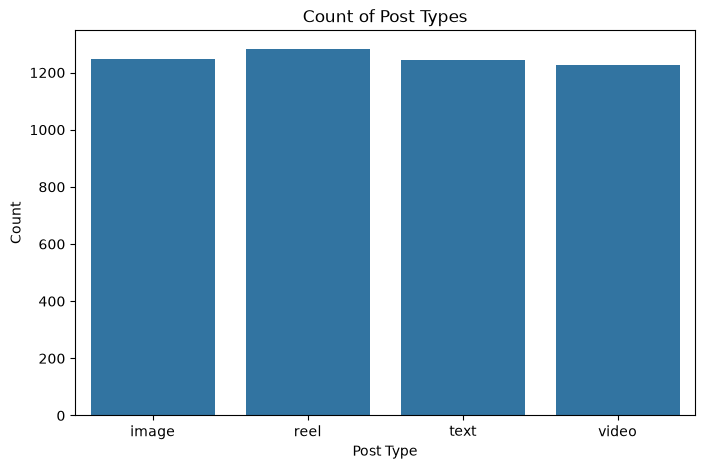

In [70]:
1#Count Plot: Post Type

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='post_type')

plt.title('Count of Post Types')

plt.xlabel('Post Type')
plt.ylabel('Count')

plt.show()

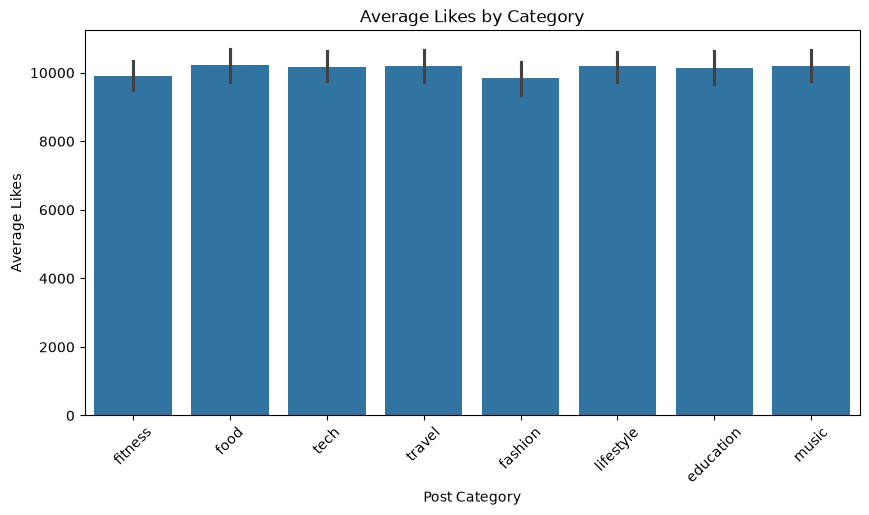

In [71]:
2#Bar Plot: Average Likes by Category

plt.figure(figsize=(10, 5))

sns.barplot(data=df, x='post_category', y='likes')

plt.title('Average Likes by Category')

plt.xlabel('Post Category')
plt.ylabel('Average Likes')

plt.xticks(rotation=45)

plt.show()

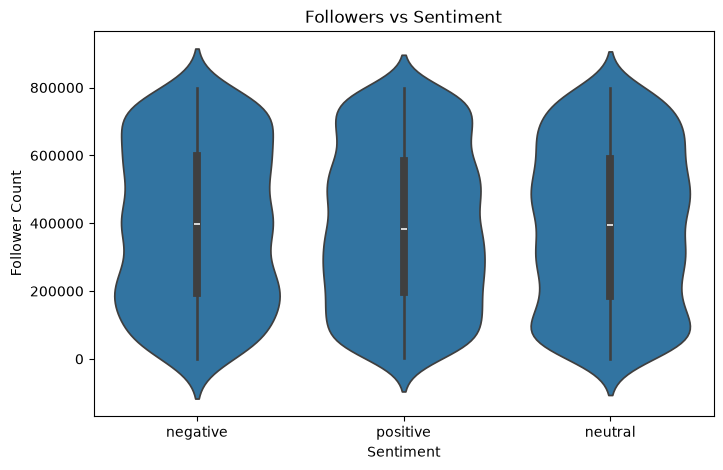

In [72]:
3#Violin Plot: Followers vs Sentiment

plt.figure(figsize=(8, 5))

sns.violinplot(data=df, x='sentiment', y='follower_count')

plt.title('Followers vs Sentiment')

plt.xlabel('Sentiment')
plt.ylabel('Follower Count')

plt.show()

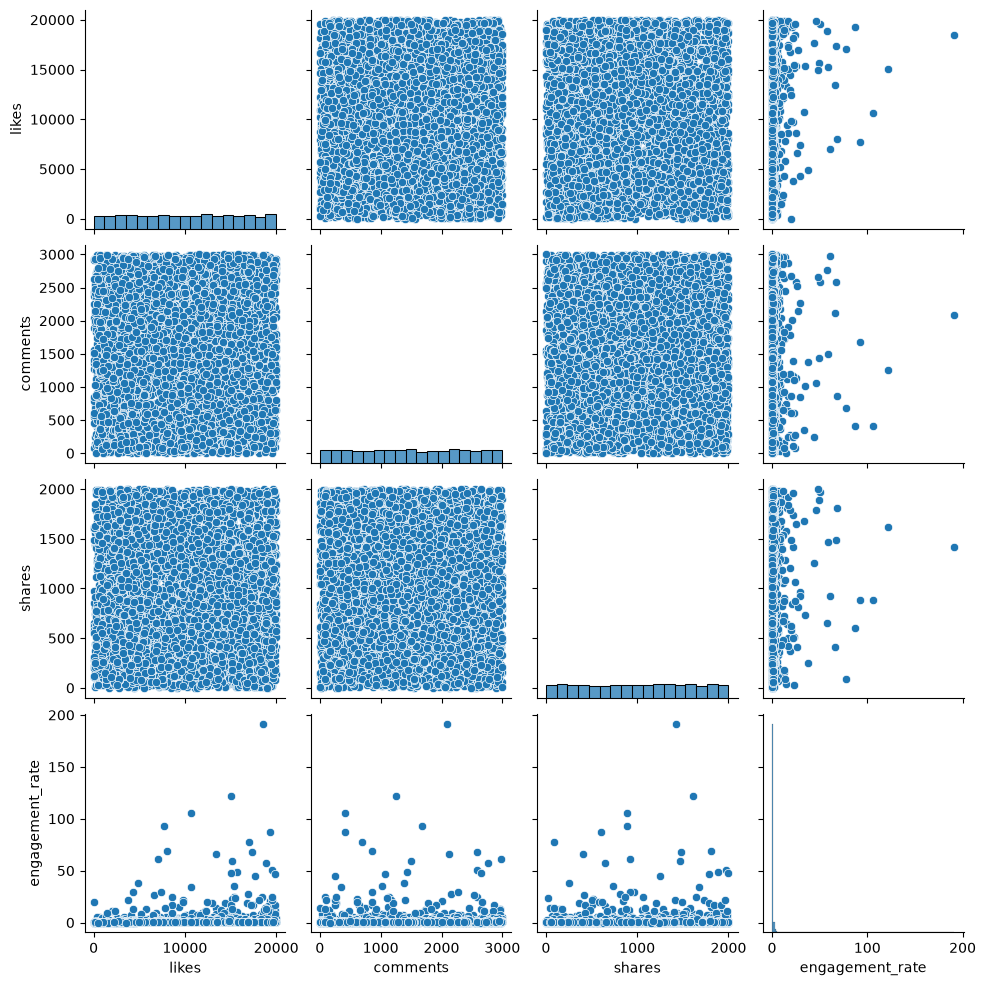

In [73]:
4#Pair Plot: Numeric Features

pair_columns = [
    'likes',
    'comments',
    'shares',
    'engagement_rate'
]

sns.pairplot(df[pair_columns])

plt.show()

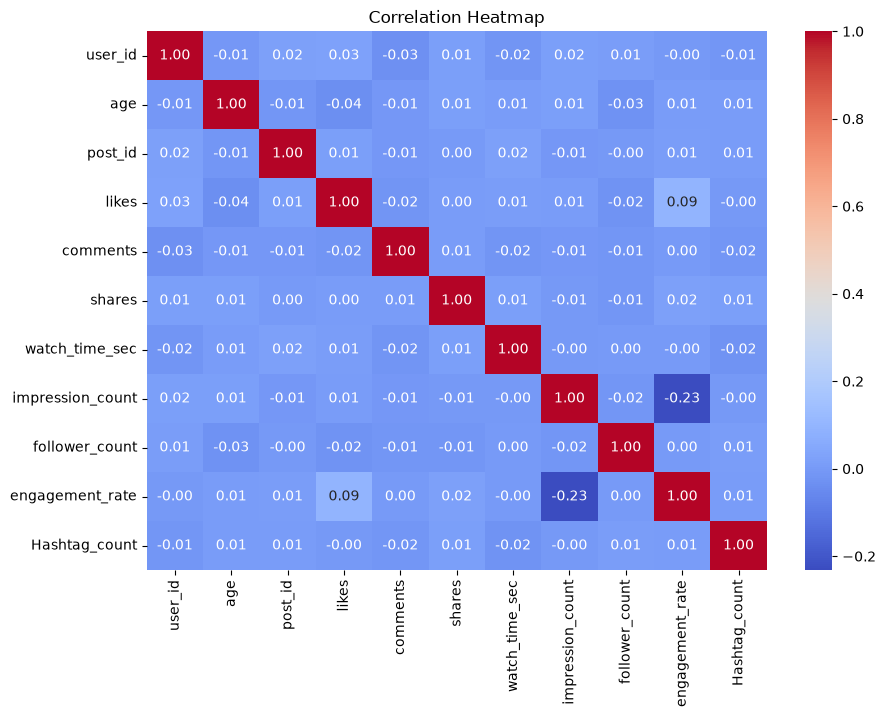

In [74]:
5#Heatmap: Correlation Matrix

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

D:\Users\ADMIN\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 68.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
D:\Users\ADMIN\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 69.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
D:\Users\ADMIN\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 68.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
D:\Users\ADMIN\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 74.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
D:\Users\ADMIN\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 75.6% of the points

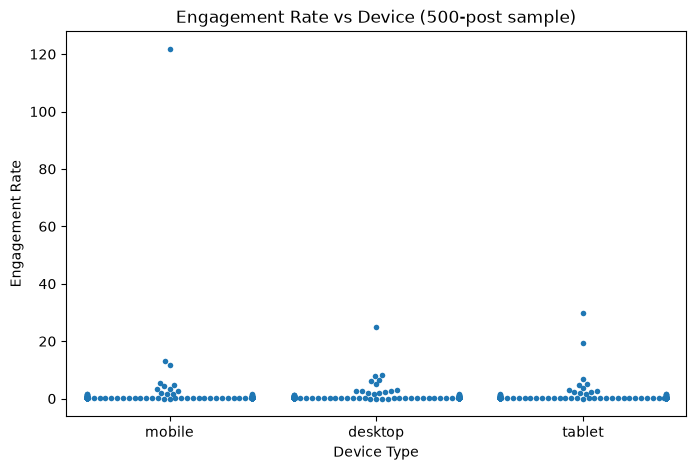

In [4]:
6#Swarm Plot: Engagement vs Device

plt.figure(figsize=(8, 5))

sns.swarmplot(
    data=df.sample(500,random_state=42),
    x='device_type',
    y='engagement_rate',
    size=4
)

plt.title('Engagement Rate vs Device (500-post sample)')

plt.xlabel('Device Type')
plt.ylabel('Engagement Rate')

plt.show() 

# **Plotly**

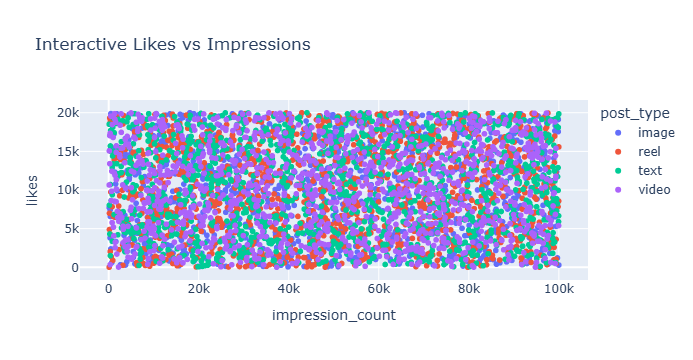

In [5]:
7#Interactive Plot using Plotly

import plotly.express as px

fig = px.scatter(
    df,
    x='impression_count',
    y='likes',
    color='post_type',
    title='Interactive Likes vs Impressions'
)

fig.show()

# **final insights**

# content performance

In [6]:
#Which post type has the highest engagement?

post_type_engagement = df.groupby('post_type')['engagement_rate'].mean()

print(post_type_engagement.sort_values(ascending=False))

post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64


In [7]:
#Which content category performs best?

category_engagement = df.groupby('post_category')['engagement_rate'].mean()

print(category_engagement.sort_values(ascending=False))

post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64


In [8]:
print(category_engagement.idxmax())

food


In [6]:
#Which countries have the highest engagement rate?

country_engagement = df.groupby('country')['engagement_rate'].mean()

print(country_engagement.sort_values(ascending=False))

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64


# User Trends

In [10]:
#How does age affect engagement?

age_engagement = df.groupby('age')['engagement_rate'].mean()

print(age_engagement)

age
13.0    0.455583
14.0    1.003067
15.0    0.714170
16.0    1.226848
17.0    0.858763
18.0    0.888391
19.0    0.676687
20.0    0.515541
21.0    0.452752
22.0    0.586786
23.0    0.922448
24.0    2.897327
25.0    1.041681
26.0    0.501467
27.0    0.775328
28.0    0.385081
29.0    1.110432
30.0    1.270129
31.0    0.440684
32.0    0.581710
33.0    1.277557
34.0    0.557236
35.0    1.521596
36.0    0.609569
37.0    0.494109
38.0    1.247501
39.0    0.436184
40.0    0.930504
41.0    1.540070
42.0    1.350772
43.0    0.566439
44.0    0.795102
45.0    0.513521
46.0    0.663994
47.0    1.402015
48.0    1.675878
49.0    0.999235
50.0    1.552627
51.0    2.397295
52.0    0.867426
53.0    0.707924
54.0    1.002622
55.0    2.599106
56.0    0.524008
57.0    0.919751
58.0    0.435130
59.0    0.495578
60.0    0.759586
61.0    0.553854
62.0    1.005127
63.0    1.303909
64.0    0.402533
Name: engagement_rate, dtype: float64


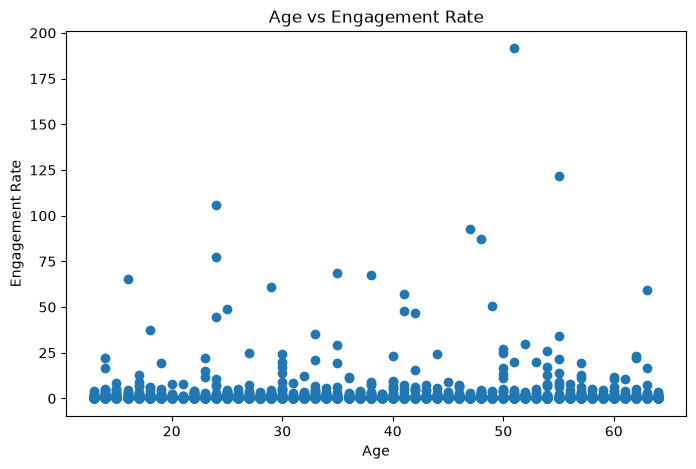

In [11]:
#Create a graph

plt.figure(figsize=(8, 5))

plt.scatter(df['age'], df['engagement_rate'])

plt.xlabel('Age')
plt.ylabel('Engagement Rate')
plt.title('Age vs Engagement Rate')

plt.show()

In [12]:
#Compare verified and unverified accounts
verified_engagement = df.groupby('is_verified')['engagement_rate'].mean()

print(verified_engagement)

is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64


# Behavioral insights

In [7]:
#Best time of day for impressions
daily_impressions = df.groupby('posted_at')['impression_count'].mean()

print(daily_impressions.sort_values(ascending=False))

posted_at
02-12-2023    98263.5
10-08-2023    90304.5
06-09-2023    89909.0
22-02-2023    84897.0
16-12-2023    81594.0
               ...   
07-10-2023    15330.0
01-08-2022    12526.0
20-12-2022    11483.0
13-10-2022     8556.0
28-08-2022     8378.0
Name: impression_count, Length: 729, dtype: float64


In [14]:
#Device type impact on watch time
device_watch_time = df.groupby('device_type')['watch_time_sec'].mean()

print(device_watch_time.sort_values(ascending=False))

device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64


# sentiment Analysis

In [15]:
#Which sentiment performs best?
sentiment_engagement = df.groupby('sentiment')['engagement_rate'].mean()

print(sentiment_engagement.sort_values(ascending=False))

sentiment
negative    1.038486
neutral     0.991170
positive    0.954800
Name: engagement_rate, dtype: float64
